In [ ]:
pip install -r ../requirements.txt --quiet

In [ ]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from hyperopt import STATUS_OK, Trials, fmin, hp, space_eval, tpe
from scipy.stats import spearmanr
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, fbeta_score, make_scorer, mean_absolute_error, mean_squared_error,
    precision_score, r2_score, recall_score, roc_auc_score
)
from sklearn.model_selection import cross_val_score
from sklearn.utils.class_weight import compute_sample_weight

from ocean_features import EVENING_FEATURES, CLASS_NAMES, GO_CLASS, evening_matrix

In [ ]:
from dotenv import load_dotenv
load_dotenv(dotenv_path='../.env', override=True)

In [ ]:
class UnifiedOceanModel:
    """
    A unified wrapper for XGBoost training, tuning, and evaluation.
    
    Supports Binary Classification (Go/No-Go), Multi-class Classification 
    (Poor/Fair/Good/Excellent), and Regression (continuous visibility).
    
    Attributes:
        data_path (Path): Filepath to the input parquet dataset.
        binary_mode (bool): If True, converts target to binary Go/No-Go.
        binary_threshold (int): Target value at or above which a day is 'Go' (3 = Excellent on the class
                                parquet, or feet on the regression parquet).
    """

    def __init__(self, data_path=None, binary_mode=False,binary_threshold=20):
        # Falls back to OCEAN_DATA_PATH from .env
        env_path = os.getenv("OCEAN_DATA_PATH")
        self.data_path = Path(data_path or env_path)
        
        self.binary_mode = binary_mode
        self.binary_threshold = binary_threshold
        
        self.model = None
        self.model_type = None 
        self.class_names = ['No-Go', 'Go'] if binary_mode else ['Poor', 'Fair', 'Good', 'Excellent']
        self.X_train, self.X_test, self.y_train, self.y_test = (None,) * 4

    def load_and_prep(self, test_size=0.2):
        """
        Loads parquet data, generates targets based on mode, and splits into train/test sets.

        Args:
            test_size (float): Proportion of dataset to include in the test split.
        """
        df = pd.read_parquet(self.data_path).sort_index()
        X = df.drop(columns=['target', 'visibility_ft'], errors='ignore')
        
        if self.binary_mode:
            # Create binary target: 1 if visibility >= threshold, else 0
            y = (df['target'] >= self.binary_threshold).astype(int)
            self.model_type = 'binary'
        else:
            y = df['target']
            unique_vals = y.nunique()
            self.model_type = 'classifier' if unique_vals <= 4 else 'regressor'
            
        print(f"--- Mode: {self.model_type.upper()}" + (f" | Go = target >= {self.binary_threshold}" if self.binary_mode else "") + " ---")
        
        # Chronological split: adjacent days are near-duplicates, so a random split leaks
        split = int(len(X) * (1 - test_size))
        self.X_train, self.X_test = X.iloc[:split], X.iloc[split:]
        self.y_train, self.y_test = y.iloc[:split], y.iloc[split:]

    def tune_hyperparameters(self, max_evals=100):
        """
        Performs Bayesian optimization using Hyperopt to find optimal XGBoost parameters.

        Optimizes for F2 score (Recall-weighted) in classification modes to minimize 
        false negatives (missing a good dive day).

        Args:
            max_evals (int): Number of iterations for the optimizer.

        Returns:
            dict: The best hyperparameters found, merged with static model configs.
        """
        space = {
            'max_depth': hp.quniform('max_depth', 3, 11, 1),
            'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.2)),
            'subsample': hp.uniform('subsample', 0.6, 1.0),
            'colsample_bytree': hp.uniform('colsample_bytree', 0.6, 1.0),
            'gamma': hp.uniform('gamma', 0, 0.7),
        }

        # Define scoring and objectives based on mode
        if self.model_type == 'binary':
            scoring = make_scorer(fbeta_score, beta=2, zero_division=0)
        elif self.model_type == 'classifier':
            scoring = make_scorer(fbeta_score, beta=2, average='macro', zero_division=0)
        else:
            scoring = 'neg_mean_absolute_error'

        def objective(params):
            params['max_depth'] = int(params['max_depth'])
            params['n_estimators'] = 300
            params['random_state'] = 42
            
            if self.model_type == 'binary':
                # Balance positive class weights
                ratio = (self.y_train == 0).sum() / max(1, (self.y_train == 1).sum())
                m = xgb.XGBClassifier(**params, objective='binary:logistic', scale_pos_weight=ratio)
            elif self.model_type == 'classifier':
                m = xgb.XGBClassifier(**params, objective='multi:softprob', num_class=4)
            else:
                m = xgb.XGBRegressor(**params, objective='reg:squarederror')
                
            score = cross_val_score(m, self.X_train, self.y_train, cv=5, scoring=scoring).mean()
            return {'loss': -score, 'status': STATUS_OK}

        best = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=max_evals, trials=Trials())
        
        # Merge optimized params with static defaults for final model construction
        best['max_depth'] = int(best['max_depth'])
        best['n_estimators'] = 300
        best['random_state'] = 42
        return best

    def predict_with_threshold(self, X, prob_threshold=0.3):
        """
        Predicts binary class using a custom probability threshold.
        
        Lowering the threshold increases Recall (catching more 'Go' days) at the 
        cost of Precision.

        Args:
            X (pd.DataFrame): Features to predict on.
            prob_threshold (float): Probability cutoff for positive class.

        Returns:
            np.array: Binary predictions (0 or 1).
        """
        if self.model_type != 'binary':
            raise ValueError("Threshold prediction only available in Binary Mode.")
        
        probs = self.model.predict_proba(X)[:, 1]
        return (probs >= prob_threshold).astype(int)
    
    def _evaluate_regressor(self, preds):
        """Internal helper to print regression metrics and plot residuals."""
        mae = mean_absolute_error(self.y_test, preds)
        rmse = np.sqrt(mean_squared_error(self.y_test, preds))
        r2 = r2_score(self.y_test, preds)
        print(f"\n--- Regression Stats (Raw Feet) ---\nMAE: {mae:.2f} ft | RMSE: {rmse:.2f} ft | R2: {r2:.4f}")
        
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        sns.regplot(x=self.y_test, y=preds, ax=axes[0], 
                    scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
        axes[0].set_xlabel("Actual Visibility (ft)")
        axes[0].set_ylabel("Predicted Visibility (ft)")
        axes[0].set_title("Actual vs. Predicted")
        
        sns.histplot(self.y_test - preds, kde=True, ax=axes[1], color='purple')
        axes[1].set_title("Residual Distribution (Errors)")
        axes[1].set_xlabel("Error (ft)")
        plt.show()

    def _evaluate_classifier(self, preds):
        """Internal helper to print classification report and confusion matrix."""
        print(f"\n--- {self.model_type.upper()} Performance ---")
        print(classification_report(self.y_test, preds, target_names=self.class_names))
        
        plt.figure(figsize=(6, 5))
        sns.heatmap(confusion_matrix(self.y_test, preds), annot=True, fmt='d', cmap='YlGnBu',
                    xticklabels=self.class_names, yticklabels=self.class_names)
        plt.title("Confusion Matrix")
        plt.show()

    def run(self, max_evals=100, prob_eval=0.4):
        """
        Executes the full training pipeline: Load -> Tune -> Fit -> Evaluate.

        Args:
            max_evals (int): Hyperopt iterations.
            prob_eval (float): Probability threshold for binary evaluation.
        """
        self.load_and_prep()
        best_p = self.tune_hyperparameters(max_evals=max_evals)
        
        if self.model_type == 'binary':
            ratio = (self.y_train == 0).sum() / max(1, (self.y_train == 1).sum())
            best_p.update({'objective': 'binary:logistic', 'scale_pos_weight': ratio})
            self.model = xgb.XGBClassifier(**best_p)
            self.model.fit(self.X_train, self.y_train)
            preds = self.predict_with_threshold(self.X_test, prob_threshold=prob_eval)
        
        elif self.model_type == 'classifier':
            best_p.update({'objective': 'multi:softprob', 'num_class': 4})
            self.model = xgb.XGBClassifier(**best_p)
            weights = compute_sample_weight(class_weight='balanced', y=self.y_train)
            self.model.fit(self.X_train, self.y_train, sample_weight=weights)
            preds = self.model.predict(self.X_test)
            
        else:
            best_p.update({'objective': 'reg:squarederror'})
            self.model = xgb.XGBRegressor(**best_p)
            self.model.fit(self.X_train, self.y_train)
            preds = self.model.predict(self.X_test)
            
        if self.model_type in ['binary', 'classifier']:
            self._evaluate_classifier(preds)
        else:
            self._evaluate_regressor(preds)
        
        importances = pd.Series(self.model.feature_importances_, index=self.X_train.columns)
        importances.sort_values().tail(15).plot(kind='barh', color='midnightblue')
        plt.title("Key Visibility Drivers")
        plt.show()

    def save(self, filename="cove_binary_model.json"):
        """Saves the trained XGBoost model to JSON."""
        if self.model: 
            self.model.save_model(filename)
            print(f"Model saved to {filename}")

--- Mode: REGRESSOR | Threshold: 20ft ---
100%|██████████| 100/100 [03:47<00:00,  2.27s/trial, best loss: 3.7393932216386125]

--- Regression Stats (Raw Feet) ---
MAE: 4.32 ft | RMSE: 5.78 ft | R2: 0.4639


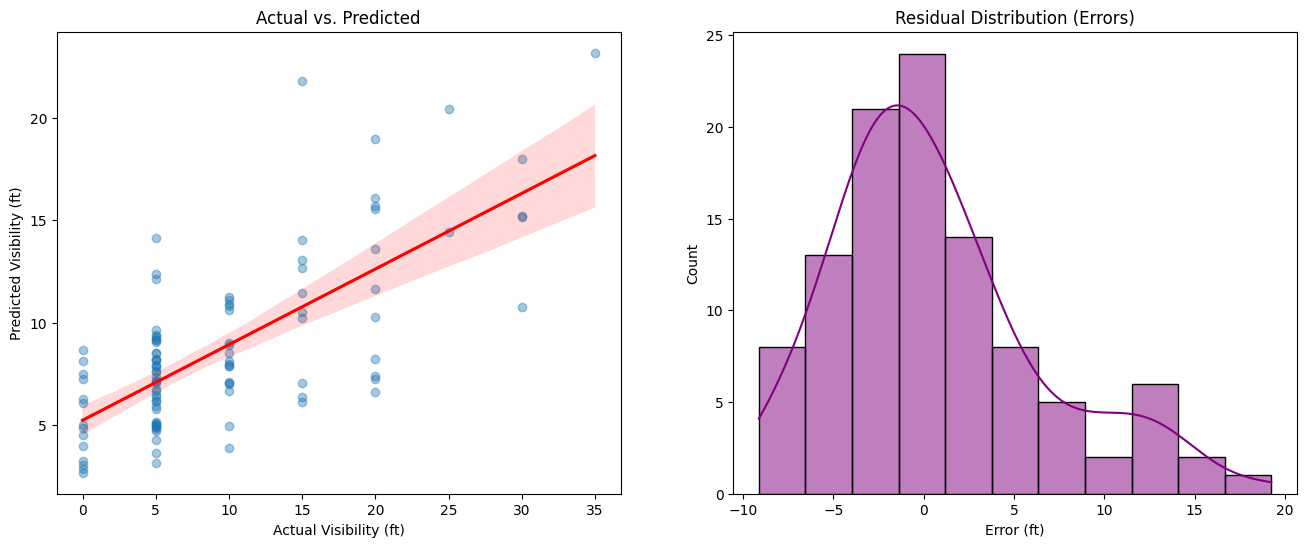

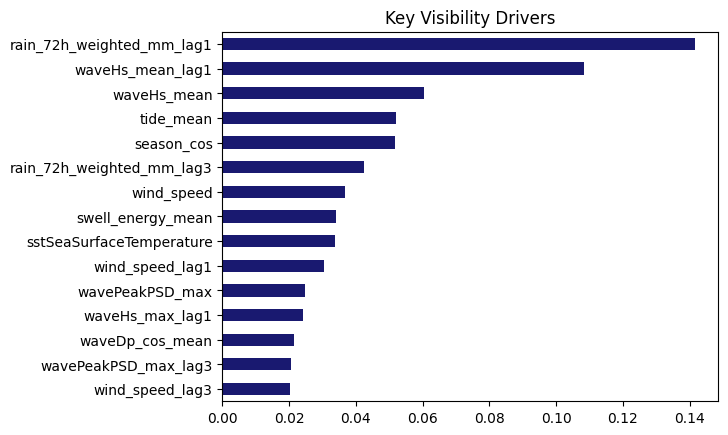

Model saved to ../data/regression_cove_model.json


In [12]:
uom = UnifiedOceanModel("../data/visibility_data_reg.parquet")
uom.run(100)
uom.save(filename= "../data/regression_cove_model.json")

--- Mode: CLASSIFIER | Threshold: 20ft ---
  0%|          | 0/100 [00:00<?, ?trial/s, best loss=?]

100%|██████████| 100/100 [05:34<00:00,  3.35s/trial, best loss: -0.4034246170421853]

--- CLASSIFIER Performance ---
              precision    recall  f1-score   support

        Poor       0.88      0.95      0.92        85
        Fair       0.20      0.11      0.14         9
        Good       0.60      0.38      0.46         8
   Excellent       0.00      0.00      0.00         2

    accuracy                           0.82       104
   macro avg       0.42      0.36      0.38       104
weighted avg       0.78      0.82      0.80       104



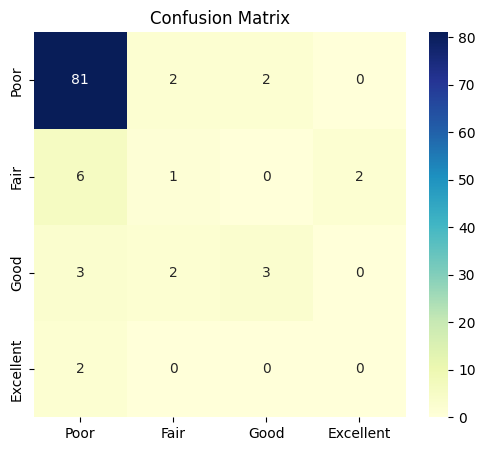

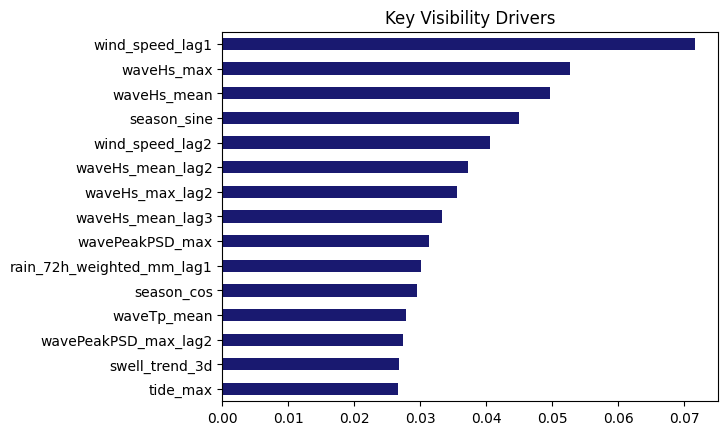

Model saved to ../data/fourClass_cove_model.json


In [6]:
uom = UnifiedOceanModel("../data/visibility_data_class.parquet")
uom.run(100)
uom.save(filename= "../data/fourClass_cove_model.json")

In [ ]:
# Go = the shop rated the day Excellent (class 3), the same definition the evening models use
uom = UnifiedOceanModel(
    data_path="../data/visibility_data_class.parquet",
    binary_mode=True,
    binary_threshold=3
)
uom.run(max_evals=100, prob_eval=0.4)
uom.save(filename="../data/binary_cove_model.json")

## Evening (8 pm) models

Small, time-validated models for predicting tomorrow's Go/No-Go and condition class from last night's pier sensor readings plus the forecast. See `EveningModels`.

In [ ]:
class EveningModels:
    """
    XGBoost models for an 8 pm run that predict tomorrow's conditions from observations only
    (yesterday's Scripps Pier turbidity/chlorophyll/CDOM, recent waves, wind, rain, SST).

    - Go/No-Go: Go means the dive shop rated the day Excellent. Tuned on average precision; the
      probability cutoff is then picked from out-of-fold F2 (recall-weighted, like the rest of this project).
    - Class: the shop's own Poor/Fair/Good/Excellent rating, tuned on macro-F1.

    There are only ~575 rated days (~50 Excellent), so everything is validated on time-ordered folds
    (adjacent days are near-duplicates, so a random split overstates skill). Hyperopt tunes on expanding
    time folds inside the training window only; backtest() wraps that in outer folds so reported scores
    never touch the data used for tuning. Pier features are NaN before Dec 2024 and XGBoost handles that,
    so earlier days still train the non-pier part of the model.
    """

    def __init__(self, data_path="../data/visibility_data_class.parquet"):
        self.data_path = Path(data_path)
        self.go_threshold = 0.5

    def load(self):
        df = pd.read_parquet(self.data_path).sort_index()
        self.X = evening_matrix(df)
        self.y_cls = df['target'].astype(int)
        self.y_go = (self.y_cls == GO_CLASS).astype(int)
        self.has_pier = self.X['pier_turbidity_med_lag1'].notna()
        print(f"{len(self.X)} rated days ({self.X.index.min().date()} to {self.X.index.max().date()}), "
              f"{int(self.has_pier.sum())} with pier data; class shares "
              f"{dict(zip(CLASS_NAMES, self.y_cls.value_counts(normalize=True).sort_index().round(3)))}")

    # ---- model building ----------------------------------------------------------------
    _MONO = ('pier_turbidity_med_lag1', 'pier_turbidity_max_lag1')

    def _space(self, task):
        space = {
            'max_depth': hp.quniform('max_depth', 2, 4, 1),
            'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.2)),
            'n_estimators': hp.quniform('n_estimators', 100, 400, 50),
            'subsample': hp.uniform('subsample', 0.6, 1.0),
            'colsample_bytree': hp.uniform('colsample_bytree', 0.6, 1.0),
            'gamma': hp.uniform('gamma', 0, 0.7),
            # Hessian-based, so tiny leaves are legitimate on a rare-positive target
            'min_child_weight': hp.loguniform('min_child_weight', np.log(0.1), np.log(5)),
            'reg_lambda': hp.loguniform('reg_lambda', np.log(0.5), np.log(20)),
            # Go: positive-class weight. Class: balanced sample weights (0/1). Both fight the imbalance.
            'weighted': hp.choice('weighted', [0, 1]),
        }
        if task == 'go':
            space['mono'] = hp.choice('mono', [0, 1])  # visibility can only fall as turbidity rises
        return space

    def _fit_predict(self, task, params, Xtr, ytr, Xte, seeds=1):
        """Fits seed-averaged models; returns (probabilities, fitted models). Tolerates a class missing from a fold."""
        classes = np.sort(ytr.unique())
        enc = {c: i for i, c in enumerate(classes)}
        kw = dict(max_depth=int(params['max_depth']), learning_rate=params['learning_rate'],
                  n_estimators=int(params['n_estimators']), subsample=params['subsample'],
                  colsample_bytree=params['colsample_bytree'], gamma=params['gamma'],
                  min_child_weight=params['min_child_weight'], reg_lambda=params['reg_lambda'])
        fit_kw = {}
        if task == 'go':
            if params['weighted']:
                kw['scale_pos_weight'] = float((ytr == 0).sum() / max((ytr == 1).sum(), 1))
            if params.get('mono'):
                kw['monotone_constraints'] = {c: -1 for c in self._MONO}
        elif params['weighted']:
            fit_kw['sample_weight'] = compute_sample_weight('balanced', ytr)

        models = [xgb.XGBClassifier(**kw, random_state=s).fit(Xtr, ytr.map(enc), **fit_kw) for s in range(seeds)]
        out = np.zeros((len(Xte), 2 if task == 'go' else 4))
        for m in models:
            pr = m.predict_proba(Xte)
            for c, i in enc.items(): out[:, c] += pr[:, i] / seeds
        return (out[:, 1] if task == 'go' else out), models

    # ---- tuning --------------------------------------------------------------------------
    def _tune(self, task, X, y, max_evals):
        """Hyperopt over expanding time folds inside (X, y); returns the best params."""
        n = len(X)
        bounds = [int(n * f) for f in (0.5, 0.67, 0.83, 1.0)]
        folds = [(slice(0, bounds[i] - 3), slice(bounds[i], bounds[i + 1])) for i in range(3)]

        def objective(params):
            scores = []
            for tr, te in folds:
                ytr, yte = y.iloc[tr], y.iloc[te]
                if ytr.nunique() < 2 or (task == 'go' and yte.nunique() < 2): continue
                p, _ = self._fit_predict(task, params, X.iloc[tr], ytr, X.iloc[te])
                scores.append(average_precision_score(yte, p) if task == 'go'
                              else f1_score(yte, p.argmax(1), average='macro'))
            return {'loss': -np.mean(scores) if scores else 0.0, 'status': STATUS_OK}

        best = fmin(objective, self._space(task), algo=tpe.suggest, max_evals=max_evals, trials=Trials(),
                    rstate=np.random.default_rng(42), show_progressbar=False)
        return space_eval(self._space(task), best)

    # ---- evaluation ----------------------------------------------------------------------
    def backtest(self, first_cut='2025-03-01', fold_days=91, max_evals=40):
        """
        Nested walk-forward evaluation. For each outer fold: tune on everything before the cut
        (3-day embargo), then score the next fold_days days that have pier data. Metrics are per
        fold (probabilities from separately trained models are not comparable when pooled), and
        go_threshold is set to the out-of-fold F2-optimal cutoff.
        """
        cuts = pd.date_range(first_cut, self.X.index.max(), freq=f"{fold_days}D")
        rows, go_oof = [], []
        for c in cuts:
            tr = self.X.index < c - pd.Timedelta(days=3)
            te = (self.X.index >= c) & (self.X.index < c + pd.Timedelta(days=fold_days)) & self.has_pier.values
            if te.sum() < 15: continue
            pg = pc = None
            for task, y in (('go', self.y_go), ('cls', self.y_cls)):
                params = self._tune(task, self.X[tr], y[tr], max_evals)
                p, _ = self._fit_predict(task, params, self.X[tr], y[tr], self.X[te], seeds=3)
                if task == 'go': pg = p
                else: pc = p
            yg, yc = self.y_go[te], self.y_cls[te]
            pred = pc.argmax(1)
            rule = -self.X.loc[te, 'pier_turbidity_med_lag1']
            r = dict(fold=str(c.date()), days=int(te.sum()), go_days=int(yg.sum()),
                     macroF1=f1_score(yc, pred, average='macro'), within1=(np.abs(pred - yc.values) <= 1).mean(),
                     rank_corr=spearmanr(yc, pc @ np.arange(4))[0], rule_rank_corr=spearmanr(yc, rule)[0])
            if yg.nunique() == 2:
                r.update(go_auc=roc_auc_score(yg, pg), go_ap=average_precision_score(yg, pg), rule_go_auc=roc_auc_score(yg, rule))
            rows.append(r)
            go_oof.append(pd.DataFrame({'p': pg, 'y': yg.values}, index=self.X.index[te]))
        res = pd.DataFrame(rows).set_index('fold')
        oof = pd.concat(go_oof)

        print(f"\n--- Nested walk-forward, per fold (pier-era days only) ---")
        print(res.round(3).to_string())
        print("\nMean over folds:"); print(res.drop(columns=['days', 'go_days']).mean().round(3).to_string())

        grid = np.arange(0.05, 0.9, 0.05)
        f2 = [fbeta_score(oof.y, (oof.p >= t).astype(int), beta=2, zero_division=0) for t in grid]
        self.go_threshold = float(grid[int(np.argmax(f2))])
        print(f"\nGo cutoff (Excellent, {int(oof.y.sum())} Go days out-of-fold):")
        print("  threshold  recall  precision   F2")
        for t, f in zip(grid, f2):
            pr = (oof.p >= t).astype(int)
            mark = '  <- chosen (max F2)' if t == self.go_threshold else ''
            print(f"    {t:.2f}     {recall_score(oof.y, pr):.2f}     {precision_score(oof.y, pr, zero_division=0):.2f}      {f:.2f}{mark}")
        return res

    # ---- final fit -----------------------------------------------------------------------
    def fit_final(self, max_evals=60):
        """Tunes on all rated days and fits the final models (3 seeds each)."""
        self.params, self.models = {}, {}
        for task, y in (('go', self.y_go), ('cls', self.y_cls)):
            self.params[task] = self._tune(task, self.X, y, max_evals)
            _, self.models[task] = self._fit_predict(task, self.params[task], self.X, y, self.X.iloc[:1], seeds=3)
            print(task, {k: (round(float(v), 4) if not isinstance(v, (int, np.integer)) else int(v)) for k, v in self.params[task].items()})

    def save(self, prefix="../data/evening"):
        """Saves one XGBoost JSON per task and seed, plus a meta file with the Go cutoff."""
        for task, models in self.models.items():
            for i, m in enumerate(models):
                m.save_model(f"{prefix}_{task}_{i}.json")
        meta = {'go_threshold': self.go_threshold, 'go_definition': CLASS_NAMES[GO_CLASS],
                'features': EVENING_FEATURES, 'seeds': {t: len(m) for t, m in self.models.items()},
                'trained_through': str(self.X.index.max().date())}
        json.dump(meta, open(f"{prefix}_meta.json", 'w'), indent=1)
        print(f"Saved {prefix}_{{go,cls}}_*.json and {prefix}_meta.json (go cutoff {self.go_threshold:.2f})")

In [ ]:
em = EveningModels()
em.load()
em.backtest(max_evals=40)
em.fit_final(max_evals=60)
em.save()